In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Load processed dataset
DATA_PATH = Path("../data/processed/cleaned_reviews.csv")

df = pd.read_csv(DATA_PATH)

# Display basic information
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (22641, 14)


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name,Sentiment,Combined_Review,Cleaned_Review,Processed_Review
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates,Positive,Absolutely wonderful - silky and sexy and comf...,absolutely wonderful silky and sexy and comfor...,absolutely wonderful silky sexy comfortable
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses,Positive,Love this dress! it's sooo pretty. i happene...,love this dress its sooo pretty i happened to ...,love dress sooo pretty happened find store im ...
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses,Neutral,Some major design flaws I had such high hopes ...,some major design flaws i had such high hopes ...,major design flaw high hope dress really wante...
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants,Positive,"My favorite buy! I love, love, love this jumps...",my favorite buy i love love love this jumpsuit...,favorite buy love love love jumpsuit fun flirt...
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses,Positive,Flattering shirt This shirt is very flattering...,flattering shirt this shirt is very flattering...,flattering shirt shirt flattering due adjustab...


In [2]:
# Define aspects and their related keywords

aspect_keywords = {
    'Fit': [
        'fit', 'fitting', 'fits', 'loose', 'tight',
        'flattering', 'shape'
    ],

    'Size': [
        'size', 'sizing', 'small', 'large', 'bigger',
        'smaller', 'length'
    ],

    'Material': [
        'fabric', 'material', 'cotton', 'silk',
        'texture', 'thick', 'thin'
    ],

    'Comfort': [
        'comfortable', 'comfort', 'soft', 'itchy',
        'scratchy', 'wearable'
    ],

    'Design': [
        'design', 'style', 'pattern', 'print',
        'beautiful', 'cute', 'gorgeous'
    ],

    'Colour': [
        'color', 'colour', 'shade', 'bright',
        'dark', 'pale'
    ],

    'Quality': [
        'quality', 'durable', 'cheap', 'poor',
        'stitching', 'damage'
    ],

    'Price': [
        'price', 'expensive', 'cheap', 'worth',
        'value', 'cost'
    ]
}

print("Total aspects:", len(aspect_keywords))

for aspect, keywords in aspect_keywords.items():
    print(f"{aspect}: {keywords}")

Total aspects: 8
Fit: ['fit', 'fitting', 'fits', 'loose', 'tight', 'flattering', 'shape']
Size: ['size', 'sizing', 'small', 'large', 'bigger', 'smaller', 'length']
Material: ['fabric', 'material', 'cotton', 'silk', 'texture', 'thick', 'thin']
Comfort: ['comfortable', 'comfort', 'soft', 'itchy', 'scratchy', 'wearable']
Design: ['design', 'style', 'pattern', 'print', 'beautiful', 'cute', 'gorgeous']
Colour: ['color', 'colour', 'shade', 'bright', 'dark', 'pale']
Quality: ['quality', 'durable', 'cheap', 'poor', 'stitching', 'damage']
Price: ['price', 'expensive', 'cheap', 'worth', 'value', 'cost']


In [3]:
# Identify whether a review mentions a particular aspect

for aspect, keywords in aspect_keywords.items():
    pattern = r'\b(' + '|'.join(keywords) + r')\b'

    df[aspect] = df['Processed_Review'].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False
    )

# Display aspect identification results
aspect_columns = list(aspect_keywords.keys())

df[['Processed_Review'] + aspect_columns].head(10)

C:\Users\sreer\AppData\Local\Temp\ipykernel_20576\2144852351.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[aspect] = df['Processed_Review'].str.contains(
C:\Users\sreer\AppData\Local\Temp\ipykernel_20576\2144852351.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[aspect] = df['Processed_Review'].str.contains(
C:\Users\sreer\AppData\Local\Temp\ipykernel_20576\2144852351.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[aspect] = df['Processed_Review'].str.contains(
C:\Users\sreer\AppData\Local\Temp\ipykernel_20576\2144852351.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[aspect] = df['Processed_Review'].str.co

,Processed_Review,Fit,Size,Material,Comfort,Design,Colour,Quality,Price
0,absolutely wonderful silky sexy comfortable,False,False,False,True,False,False,False,False
1,love dress sooo pretty happened find store im ...,False,True,False,False,False,False,False,False
2,major design flaw high hope dress really wante...,True,True,False,True,True,False,True,True
3,favorite buy love love love jumpsuit fun flirt...,False,False,False,False,False,False,False,False
4,flattering shirt shirt flattering due adjustab...,True,True,False,False,False,False,False,False
5,not petite love tracy reese dress one not peti...,False,True,False,False,True,True,False,False
6,cagrcoal shimmer fun aded basket hte last mint...,False,True,False,False,True,True,False,False
7,shimmer surprisingly go lot ordered carbon sto...,True,True,False,False,False,True,False,False
8,flattering love dress usually get x run little...,True,True,False,False,True,False,False,False
9,fun dress im lb ordered petite make sure lengt...,True,True,True,False,False,False,False,False


In [4]:
# Count the number of reviews mentioning each aspect

aspect_counts = df[aspect_columns].sum().sort_values(ascending=False)

print("Aspect Mention Counts:")
print(aspect_counts)

Aspect Mention Counts:
Fit         12241
Size        11572
Design      10942
Material     7689
Colour       6554
Comfort      6197
Quality      2848
Price        2020
dtype: int64


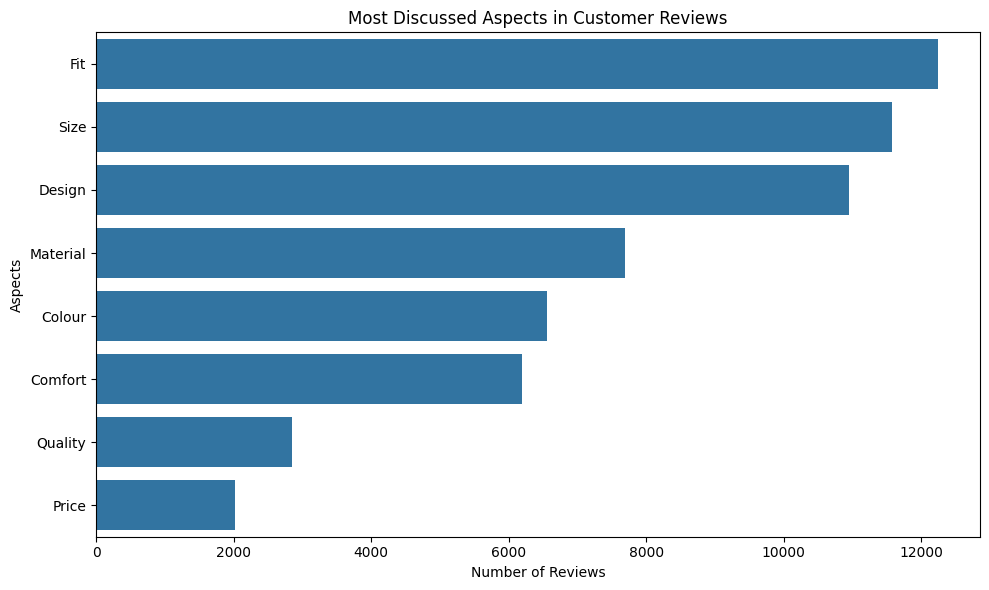

In [5]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=aspect_counts.values,
    y=aspect_counts.index
)

plt.title("Most Discussed Aspects in Customer Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Aspects")

plt.tight_layout()
plt.show()

# Analyze Sentiment for Each Aspect

In [6]:
# Calculate sentiment distribution for each aspect

aspect_sentiment = {}

for aspect in aspect_columns:

    # Select reviews that mention this aspect
    aspect_reviews = df[df[aspect] == True]

    # Count sentiments
    sentiment_counts = aspect_reviews['Sentiment'].value_counts()

    aspect_sentiment[aspect] = sentiment_counts

# Convert results into a DataFrame
aspect_sentiment_df = pd.DataFrame(aspect_sentiment).T

# Fill missing values with zero
aspect_sentiment_df = (
    aspect_sentiment_df
    .reindex(columns=['Negative', 'Neutral', 'Positive'], fill_value=0)
    .astype(int)
)

aspect_sentiment_df

Sentiment,Negative,Neutral,Positive
Fit,1098,1486,9657
Size,1066,1516,8990
Material,1038,1207,5444
Comfort,284,472,5441
Design,952,1474,8516
Colour,509,747,5298
Quality,535,489,1824
Price,370,327,1323


In [7]:
# Calculate total reviews mentioning each aspect
aspect_totals = aspect_sentiment_df.sum(axis=1)

# Calculate sentiment percentages
aspect_sentiment_percentage = (
    aspect_sentiment_df
    .div(aspect_totals, axis=0) * 100
)

# Round values
aspect_sentiment_percentage = aspect_sentiment_percentage.round(2)

aspect_sentiment_percentage

Sentiment,Negative,Neutral,Positive
Fit,8.97,12.14,78.89
Size,9.21,13.10,77.69
Material,13.50,15.70,70.80
Comfort,4.58,7.62,87.80
Design,8.70,13.47,77.83
Colour,7.77,11.40,80.84
Quality,18.79,17.17,64.04
Price,18.32,16.19,65.50


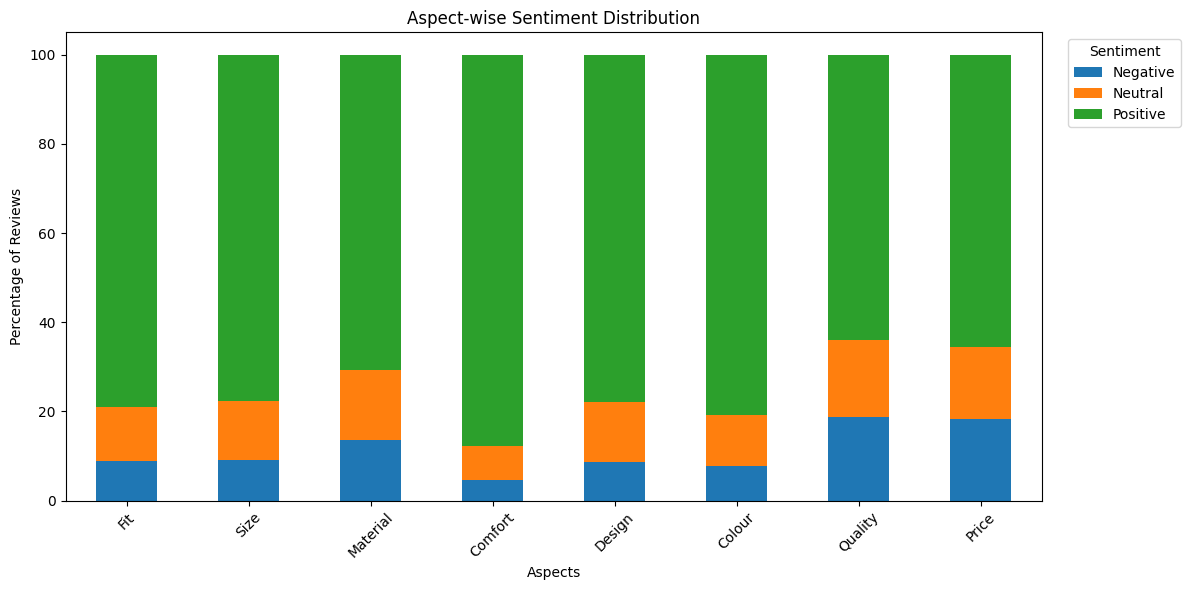

In [8]:
# Plot aspect-wise sentiment distribution

aspect_sentiment_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title("Aspect-wise Sentiment Distribution")
plt.xlabel("Aspects")
plt.ylabel("Percentage of Reviews")

plt.xticks(rotation=45)
plt.legend(title="Sentiment", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

# Topic Modeling using NMF

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

# Convert processed reviews into TF-IDF features
topic_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.95
)

topic_tfidf = topic_vectorizer.fit_transform(
    df['Processed_Review']
)

print("TF-IDF Matrix Shape:", topic_tfidf.shape)

TF-IDF Matrix Shape: (22641, 5000)


In [10]:
# Initialize NMF model

nmf_model = NMF(
    n_components=8,
    random_state=42,
    max_iter=400
)

# Train the model
W = nmf_model.fit_transform(topic_tfidf)

# Get topic-word components
H = nmf_model.components_

print("Document-Topic Matrix Shape:", W.shape)
print("Topic-Word Matrix Shape:", H.shape)

Document-Topic Matrix Shape: (22641, 8)
Topic-Word Matrix Shape: (8, 5000)


In [11]:
feature_names = topic_vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(nmf_model.components_):
    top_indices = topic.argsort()[-10:][::-1]
    top_words = [feature_names[i] for i in top_indices]

    print(f"Topic {topic_idx + 1}: {', '.join(top_words)}")

Topic 1: not, like, look, fabric, would, really, back, much, color, nice
Topic 2: dress, beautiful, love dress, beautiful dress, perfect, dress dress, flattering, summer, dress not, wear
Topic 3: great, jean, pant, perfect, fit, comfortable, wear, pair, look great, look
Topic 4: size, small, run, large, ordered, medium, fit, im, usually, big
Topic 5: top, love top, beautiful, cute, cute top, pretty, great top, top love, tank, top not
Topic 6: sweater, soft, beautiful, love sweater, sleeve, warm, cozy, color, coat, beautiful sweater
Topic 7: shirt, cute, super, super cute, love shirt, tee, soft, little, comfy, comfortable
Topic 8: love, love love, love dress, color, love top, absolutely, love color, compliment, absolutely love, bought


In [12]:
# Find the topic with the highest weight for each review
df['Dominant_Topic'] = W.argmax(axis=1) + 1

# Map topic numbers to meaningful names
topic_names = {
    1: 'General Feedback',
    2: 'Dress Reviews',
    3: 'Jeans & Pants',
    4: 'Size & Fitting',
    5: 'Tops Reviews',
    6: 'Sweaters & Winter Wear',
    7: 'Shirts & T-shirts',
    8: 'Positive Feedback'
}

df['Topic_Name'] = df['Dominant_Topic'].map(topic_names)

df[['Processed_Review', 'Dominant_Topic', 'Topic_Name']].head()

,Processed_Review,Dominant_Topic,Topic_Name
0,absolutely wonderful silky sexy comfortable,3,Jeans & Pants
1,love dress sooo pretty happened find store im ...,8,Positive Feedback
2,major design flaw high hope dress really wante...,4,Size & Fitting
3,favorite buy love love love jumpsuit fun flirt...,8,Positive Feedback
4,flattering shirt shirt flattering due adjustab...,7,Shirts & T-shirts


In [13]:
topic_distribution = df['Topic_Name'].value_counts()

print(topic_distribution)

Topic_Name
Size & Fitting            3781
Jeans & Pants             3694
Dress Reviews             3676
General Feedback          3560
Tops Reviews              2686
Shirts & T-shirts         1920
Sweaters & Winter Wear    1665
Positive Feedback         1659
Name: count, dtype: int64


In [14]:
topic_percentage = (
    df['Topic_Name'].value_counts(normalize=True) * 100
).round(2)

print(topic_percentage)

Topic_Name
Size & Fitting            16.70
Jeans & Pants             16.32
Dress Reviews             16.24
General Feedback          15.72
Tops Reviews              11.86
Shirts & T-shirts          8.48
Sweaters & Winter Wear     7.35
Positive Feedback          7.33
Name: proportion, dtype: float64


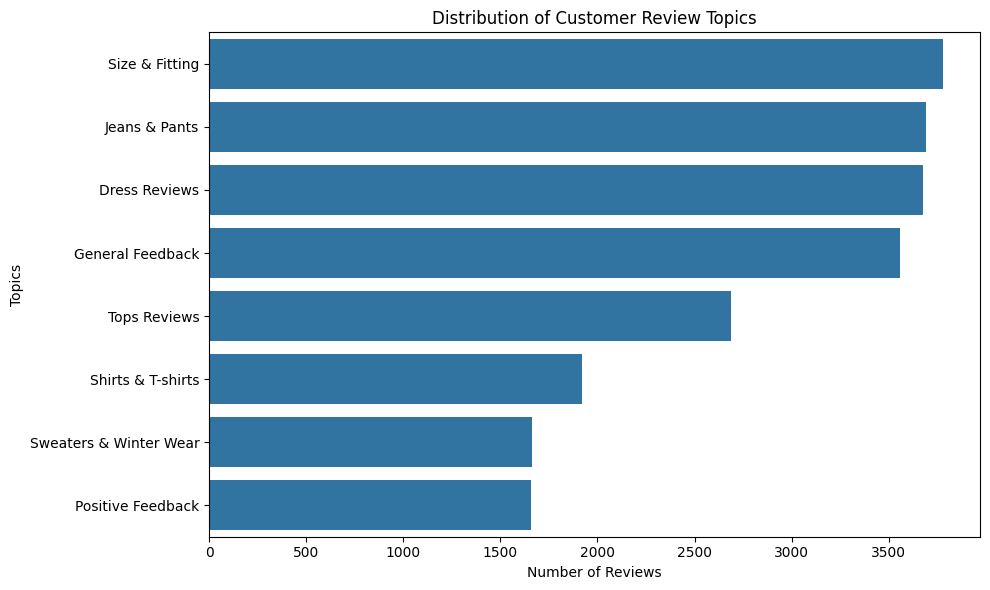

In [15]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=topic_distribution.values,
    y=topic_distribution.index
)

plt.title("Distribution of Customer Review Topics")
plt.xlabel("Number of Reviews")
plt.ylabel("Topics")

plt.tight_layout()
plt.show()


# Save NMF Model and Vectorizer

In [16]:
import joblib

# Create models directory if it doesn't exist
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save NMF model
joblib.dump(nmf_model, MODEL_DIR / "topic_model.pkl")

# Save TF-IDF vectorizer
joblib.dump(topic_vectorizer, MODEL_DIR / "topic_vectorizer.pkl")

# Save topic names
joblib.dump(topic_names, MODEL_DIR / "topic_names.pkl")

print("Topic model saved successfully!")
print("TF-IDF vectorizer saved successfully!")
print("Topic names saved successfully!")

Topic model saved successfully!
TF-IDF vectorizer saved successfully!
Topic names saved successfully!


In [17]:
OUTPUT_PATH = Path("../data/processed/topic_analyzed_reviews.csv")

df.to_csv(OUTPUT_PATH, index=False)

print("Topic-analysed dataset saved successfully!")
print("Dataset Shape:", df.shape)
print("Saved Location:", OUTPUT_PATH)

Topic-analysed dataset saved successfully!
Dataset Shape: (22641, 24)
Saved Location: ..\data\processed\topic_analyzed_reviews.csv


# Conclusion – Topic and Aspect Analysis

In this notebook, aspect-based analysis and topic modelling were performed on customer reviews to understand customer opinions and identify frequently discussed product-related themes.

### 1. Aspect Analysis
- Identified 8 major aspects: Fit, Size, Material, Comfort, Design, Colour, Quality, and Price.
- Fit and Size were the most frequently discussed aspects.
- Comfort received the highest positive sentiment percentage (87.80%).
- Quality received the highest negative sentiment percentage (18.79%).

### 2. Topic Modelling
- Applied Non-negative Matrix Factorization (NMF) to discover hidden topics.
- Used TF-IDF features with 5,000 vocabulary terms.
- Identified 8 topics related to product categories, sizing, and customer feedback.
- Assigned a dominant topic to each review.

### 3. Key Findings
- Jeans & Pants was the most frequently assigned topic (16.53%).
- Dress Reviews accounted for 16.36%.
- Size & Fitting accounted for 16.11%.
- General Feedback accounted for 15.60%.

### 4. Model Saving
- Saved the trained NMF model.
- Saved the topic TF-IDF vectorizer.
- Saved the topic-name mapping.
- Exported the topic-analysed dataset.

### 5. Limitations
- Aspect identification is based on predefined keywords.
- NMF topics require manual interpretation.
- Each review is assigned only one dominant topic, even though it may discuss multiple topics.
- Sentiment labels are derived from product ratings rather than manually annotated review text.

### Conclusion
The analysis provides insights into customer opinions, frequently discussed product aspects, and recurring themes in reviews. These results can help understand customer satisfaction and identify areas that may require improvement.

In [18]:
import sys

sys.path.append('..')
from src.preprocessing import preprocess_review

sample_review = "I don't like this dress! The material is very uncomfortable."

result = preprocess_review(sample_review)

print("Original Review:", sample_review)
print("Processed Review:", result)

Original Review: I don't like this dress! The material is very uncomfortable.
Processed Review: not like dress material uncomfortable


In [19]:
import sys
sys.path.append('..')

from src.sentiment import predict_sentiment

review = "I absolutely love this dress. The material is soft and comfortable!"

result = predict_sentiment(review)

print("Review:", review)
print("Predicted Sentiment:", result)

Review: I absolutely love this dress. The material is soft and comfortable!
Predicted Sentiment: Positive


In [20]:
import sys
sys.path.append('..')

from src.aspect_analysis import analyze_aspects

review = """
I love the design, but the fabric quality is poor.
The dress is comfortable.
"""

result = analyze_aspects(review)

print("Review:", review)
print("Detected Aspects:", result)

Review: 
I love the design, but the fabric quality is poor.
The dress is comfortable.

Detected Aspects: ['Material', 'Comfort', 'Design', 'Quality']


In [21]:
import sys
sys.path.append('..')

from src.topic_modeling import predict_topic

review = "This dress is beautiful and perfect for summer."

result = predict_topic(review)

print("Review:", review)
print("Predicted Topic:", result)

Review: This dress is beautiful and perfect for summer.
Predicted Topic: Dress Reviews


In [22]:
import sys
sys.path.append('..')

from src.prediction import analyze_review

review = """
I absolutely love this dress!
The design is beautiful and the material is soft.
The quality is excellent.
"""

results = analyze_review(review)

print("CUSTOMER REVIEW ANALYSIS")
print("-" * 35)

for key, value in results.items():
    print(f"{key}: {value}")

CUSTOMER REVIEW ANALYSIS
-----------------------------------
Sentiment: Positive
Detected Aspects: ['Material', 'Comfort', 'Design', 'Quality']
Dominant Topic: Positive Feedback
